<a href="https://colab.research.google.com/github/angelinephilo/nasaspaceapps26/blob/main/Climate_Projections_FINAL.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

%cd /content/drive/MyDrive/climate-app


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
/content/drive/MyDrive/climate-app
data


In [ ]:
pip install requests pandas xarray s3fs netCDF4 urllib3

In [6]:
import requests ##run
from requests.adapters import HTTPAdapter
from urllib3.util.retry import Retry
import pandas as pd
import numpy as np
from multiprocessing.pool import ThreadPool

import xarray as xr
import s3fs
import netCDF4
from netCDF4 import Dataset

import os
import os.path

In [8]:
import os
from pathlib import Path

MODEL, VARIANT, GRID = "GFDL-ESM4", "r1i1p1f1", "gr1"
BUCKET = "nex-gddp-cmip6"
VARS = ["pr", "tasmin", "tasmax"]
LAT, LON = (-12, 38), (60, 145)

DATA = Path(os.environ.get("CLIMATE_DATA", "/content/drive/MyDrive/climate-app/data"))
ANNUAL_DIR = DATA / "annual"
STATS_DIR = DATA / "stats"

BASELINE = ("historical", range(1995, 2015))
SCENARIOS = ["ssp126", "ssp585"]
PERIODS = {"2026-2040": range(2026, 2041), "2041-2060": range(2041, 2061),
           "2061-2080": range(2061, 2081), "2081-2100": range(2081, 2101)}

UNITS = {"pr_m": "mm/month", "tasmin_m": "degC", "tasmax_m": "degC",
         "rx1day": "mm/day", "hotdays35": "days/year"}

STATS_UNITS = {"pr_monthly": "mm/month", "tasmin_monthly": "degC", "tasmax_monthly": "degC",
               "pr_annual": "mm/year", "tasmin_annual": "degC", "tasmax_annual": "degC",
               "rx1day": "mm/day", "hotdays35": "days/year"}

DELTA_VARS = ["pr_annual", "tasmin_annual", "tasmax_annual", "rx1day", "hotdays35"]
DELTA_UNITS = {"pr_annual": "mm/year", "tasmin_annual": "degC", "tasmax_annual": "degC",
               "rx1day": "mm/day", "hotdays35": "days/year", "pr_pct": "%"}
MIN_BASE_RAIN = 50  # mm/yr; below this, % change is meaningless (deserts)

In [9]:
import time ##lowk can ignore this cell cos the files exist but it doesnt disrupt runtime
import s3fs, xarray as xr

fs = s3fs.S3FileSystem(anon=True)

def open_var(exp, var, year):
    for suffix in ("", "_v1.1"):
        k = (f"{BUCKET}/NEX-GDDP-CMIP6/{MODEL}/{exp}/{VARIANT}/{var}/"
             f"{var}_day_{MODEL}_{exp}_{VARIANT}_{GRID}_{year}{suffix}.nc")
        if fs.exists(k):
            return xr.open_dataset(fs.open(k), engine="h5netcdf")
    raise FileNotFoundError(f"No file found for {exp} {var} {year} (check config / bucket listing)")

def process(exp, year):
    out = ANNUAL_DIR / f"{exp}_{year}.nc"
    if out.exists():
        return
    d = {v: open_var(exp, v, year)[v].sel(lat=slice(*LAT), lon=slice(*LON)).load() for v in VARS}
    pr, tmin, tmax = d["pr"] * 86400, d["tasmin"] - 273.15, d["tasmax"] - 273.15
    ds = xr.Dataset({
        "pr_m": pr.groupby("time.month").sum("time", min_count=1),
        "tasmin_m": tmin.groupby("time.month").mean("time"),
        "tasmax_m": tmax.groupby("time.month").mean("time"),
        "rx1day": pr.max("time"),
        "hotdays35": (tmax > 35).sum("time"),
    })
    mask = tmax.isel(time=0).notnull().drop_vars("time")
    ds = ds.where(mask).astype("float32")
    for v, u in UNITS.items():
        ds[v].attrs = {"units": u}
    ANNUAL_DIR.mkdir(parents=True, exist_ok=True)
    tmp = out.with_suffix(".tmp")
    ds.to_netcdf(tmp)
    tmp.rename(out)

def run(exps=None, test=True):
    # exps = which runs to process, e.g. ["historical", "ssp126"]
    jobs = [("historical", y) for y in BASELINE[1]]
    for s in SCENARIOS:
        jobs += [(s, y) for p in PERIODS.values() for y in p]
    if exps:
        jobs = [j for j in jobs if j[0] in exps]
    if test:
        jobs = jobs[:1]
    for i, (exp, y) in enumerate(jobs, 1):
        for attempt in range(3):
            try:
                t = time.time(); process(exp, y)
                print(f"[{i}/{len(jobs)}] {exp} {y} ok ({time.time()-t:.0f}s)", flush=True); break
            except Exception as e:
                print(f"  retry {attempt+1} for {exp} {y}: {e}", flush=True); time.sleep(5)

In [ ]:
#run(test=True)  ###the full run takes 8 hours
#run(exps=["historical", "ssp126"], test=False)
#run(exps=["ssp585"], test=False)

In [10]:
import os
import pandas as pd

def stack(exp, years):
    files = [ANNUAL_DIR / f"{exp}_{y}.nc" for y in years]
    missing = [f.name for f in files if not f.exists()]
    if missing:
        raise SystemExit(f"Missing {len(missing)} files, e.g. {missing[:3]} - re-run run(...)")
    dss = []
    for f in files:
        with xr.open_dataset(f) as src:   # closes the file after loading
            dss.append(src.load())
    return xr.concat(dss, dim=pd.Index(list(years), name="year"))

STATS_UNITS = {"pr_monthly": "mm/month", "tasmin_monthly": "degC", "tasmax_monthly": "degC",
               "pr_annual": "mm/year", "tasmin_annual": "degC", "tasmax_annual": "degC",
               "rx1day": "mm/day", "hotdays35": "days/year"}

def summarise_stats(ds):
    pr_a = ds.pr_m.sum("month", min_count=1)
    tmin_a, tmax_a = ds.tasmin_m.mean("month"), ds.tasmax_m.mean("month")
    mask = ds.rx1day.isel(year=0).notnull()
    out = xr.Dataset({
        "pr_monthly": ds.pr_m.mean("year"), "tasmin_monthly": ds.tasmin_m.mean("year"),
        "tasmax_monthly": ds.tasmax_m.mean("year"),
        "pr_annual": pr_a.mean("year"), "tasmin_annual": tmin_a.mean("year"),
        "tasmax_annual": tmax_a.mean("year"),
        "rx1day": ds.rx1day.mean("year"), "hotdays35": ds.hotdays35.mean("year"),
        "pr_wettest_year": pr_a.fillna(-1).idxmax("year"),
        "pr_driest_year": pr_a.fillna(1e9).idxmin("year"),
        "tmax_hottest_year": tmax_a.fillna(-99).idxmax("year"),
    }).where(mask)
    for v, u in STATS_UNITS.items():      # set AFTER where(), which can drop attrs
        out[v].attrs = {"units": u}
    return out

def save_nc(ds, path):
    for v in ds.data_vars:
        ds[v].encoding = {}                 # drop stale encoding from the source files
    enc = {v: {"zlib": True, "complevel": 5, "shuffle": True} for v in ds.data_vars}
    tmp = path.with_suffix(".tmp")
    ds.to_netcdf(tmp, encoding=enc)
    os.replace(tmp, path)
    print(f"  {path.name}: {path.stat().st_size / 1e6:.1f} MB")

STATS_DIR.mkdir(parents=True, exist_ok=True)
save_nc(summarise_stats(stack(*BASELINE)), STATS_DIR / "baseline.nc"); print("baseline done")
for s in SCENARIOS:
    for name, yrs in PERIODS.items():
        try:
            save_nc(summarise_stats(stack(s, yrs)), STATS_DIR / f"{s}_{name}.nc")
            print(s, name, "done")
        except SystemExit as e:
            print(s, name, "skipped:", e)

  baseline.nc: 3.7 MB
baseline done
  ssp126_2026-2040.nc: 3.7 MB
ssp126 2026-2040 done
  ssp126_2041-2060.nc: 3.7 MB
ssp126 2041-2060 done
  ssp126_2061-2080.nc: 3.7 MB
ssp126 2061-2080 done
  ssp126_2081-2100.nc: 3.7 MB
ssp126 2081-2100 done
  ssp585_2026-2040.nc: 3.7 MB
ssp585 2026-2040 done
  ssp585_2041-2060.nc: 3.7 MB
ssp585 2041-2060 done
  ssp585_2061-2080.nc: 3.7 MB
ssp585 2061-2080 done
  ssp585_2081-2100.nc: 3.7 MB
ssp585 2081-2100 done


  delta_ssp126_2026-2040.nc: 0.5 MB
ssp126 2026-2040 delta done
  delta_ssp126_2041-2060.nc: 0.5 MB
ssp126 2041-2060 delta done
  delta_ssp126_2061-2080.nc: 0.5 MB
ssp126 2061-2080 delta done
  delta_ssp126_2081-2100.nc: 0.5 MB
ssp126 2081-2100 delta done
  delta_ssp585_2026-2040.nc: 0.5 MB
ssp585 2026-2040 delta done
  delta_ssp585_2041-2060.nc: 0.5 MB
ssp585 2041-2060 delta done
  delta_ssp585_2061-2080.nc: 0.5 MB
ssp585 2061-2080 delta done
  delta_ssp585_2081-2100.nc: 0.5 MB
ssp585 2081-2100 delta done


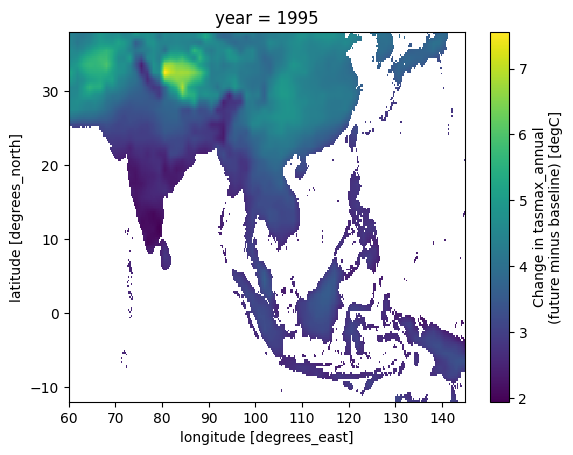

In [11]:
DELTA_VARS = ["pr_annual", "tasmin_annual", "tasmax_annual", "rx1day", "hotdays35"]
DELTA_UNITS = {"pr_annual": "mm/year", "tasmin_annual": "degC", "tasmax_annual": "degC",
               "rx1day": "mm/day", "hotdays35": "days/year", "pr_pct": "%"}
MIN_BASE_RAIN = 50   # mm/yr; below this, % change is meaningless (deserts)

def build_delta(scn, period):
    with xr.open_dataset(STATS_DIR / "baseline.nc") as b, \
         xr.open_dataset(STATS_DIR / f"{scn}_{period}.nc") as f:
        b, f = b.load(), f.load()
    d = f[DELTA_VARS] - b[DELTA_VARS]
    d["pr_pct"] = (100 * (f.pr_annual - b.pr_annual) / b.pr_annual).where(b.pr_annual >= MIN_BASE_RAIN)
    for v, u in DELTA_UNITS.items():
        d[v].attrs = {"units": u, "long_name": f"Change in {v} (future minus baseline)"}
    return d

for s in SCENARIOS:
    for name in PERIODS:
        save_nc(build_delta(s, name), STATS_DIR / f"delta_{s}_{name}.nc")
        print(s, name, "delta done")



In [12]:
for f in sorted(STATS_DIR.glob("*.nc")):
    print(f"{f.name}: {f.stat().st_size/1e6:.1f} MB")

baseline.nc: 3.7 MB
delta_ssp126_2026-2040.nc: 0.5 MB
delta_ssp126_2041-2060.nc: 0.5 MB
delta_ssp126_2061-2080.nc: 0.5 MB
delta_ssp126_2081-2100.nc: 0.5 MB
delta_ssp585_2026-2040.nc: 0.5 MB
delta_ssp585_2041-2060.nc: 0.5 MB
delta_ssp585_2061-2080.nc: 0.5 MB
delta_ssp585_2081-2100.nc: 0.5 MB
ssp126_2026-2040.nc: 3.7 MB
ssp126_2041-2060.nc: 3.7 MB
ssp126_2061-2080.nc: 3.7 MB
ssp126_2081-2100.nc: 3.7 MB
ssp585_2026-2040.nc: 3.7 MB
ssp585_2041-2060.nc: 3.7 MB
ssp585_2061-2080.nc: 3.7 MB
ssp585_2081-2100.nc: 3.7 MB
